# Handwritten Digit Recognition with Auto-Encoder Enhanced Neural Networks

## Introduction

This project explores the development and application of autoencoders for image denoising, leveraging neural networks to both compress and reconstruct data. Utilizing the MNIST dataset, which comprises 70,000 labeled images of handwritten digits, we artificially introduce noise to these images and train an autoencoder to cleanse this noise. Post-denoising, a classifier is employed to recognize the digits, evaluating its accuracy on both the original noisy images and the purified outputs. This endeavor not only offers practical experience with autoencoders and image denoising techniques but also delves into foundational deep learning concepts, including neural networks and unsupervised learning.

Key technologies used include:
- TensorFlow and Keras for building the neural network
- NumPy for numerical operations
- Matplotlib for visualizing the results

## Importing Libraries

In [1]:
#python modules
import numpy as np
from tensorflow.keras.datasets import mnist
from matplotlib import pyplot as plt
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping, LambdaCallback
from tensorflow.keras.utils import to_categorical

%matplotlib inline

## Data Preprocessing


In [2]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# convert the images to float32 and normalize them
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')
x_train /= 255.
x_test /= 255.

# reshape the images to a 4-dimensional tensor with shape (samples, width, height, channels)
x_train = x_train.reshape((60000, 784))
x_test = x_test.reshape((10000, 784))

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


## Adding Noise to the Image

In [3]:
# add noise to the training and testing images
noise_factor = 0.9
x_train_noisy = x_train + np.random.rand(60000, 28 * 28) * noise_factor
x_test_noisy = x_test + np.random.rand(10000, 28 * 28) * noise_factor

# clip the values of the noisy images to be between 0 and 1
x_train_noisy = np.clip(x_train_noisy, 0., 1.)
x_test_noisy = np.clip(x_test_noisy, 0., 1.)

In [4]:
def plot(x, p, labels = False):
    """
    Plots a set of images along with their predicted labels.

    Parameters
    ----------
    x : np.ndarray
        A numpy array of shape (n_images, height, width) containing the images to be plotted.
    p : np.ndarray, optional
        A numpy array of shape (n_images, num_classes) containing the predicted labels for each image, by default None.
    labels : bool, optional
        A boolean indicating whether to plot the predicted labels alongside the images, by default False.

    Returns
    -------
    None
    """
    plt.figure(figsize=(20,2))
    for i in range(10):
        plt.subplot(1,10,i+1)
        plt.imshow(x[i].reshape(28,28), cmap='binary')
        plt.xticks([])
        plt.yticks([])
        if labels:
            plt.xlabel(np.argmax(p[i]))
    plt.show()
    return

### Plot some clean images

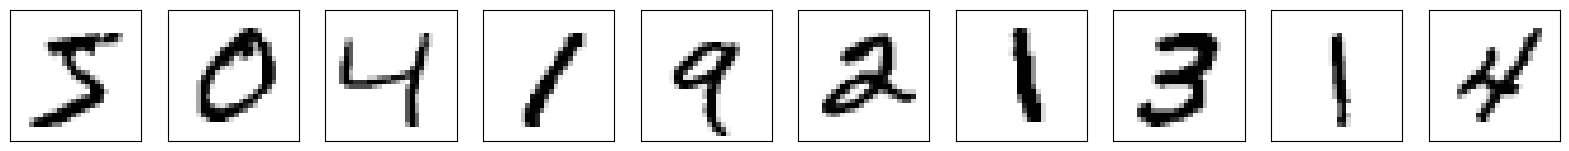

In [5]:
plot(x_train, None)

### Plot some noisy images

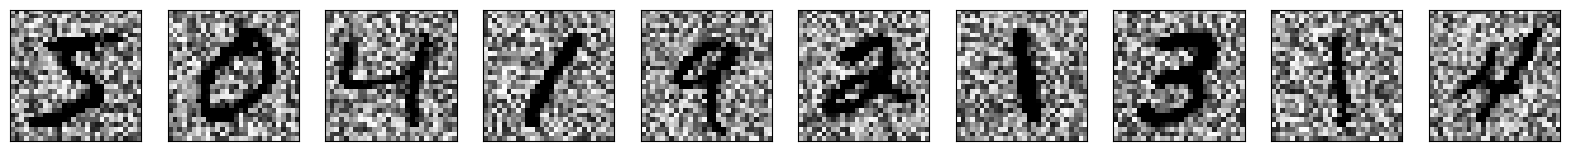

In [6]:
plot(x_train_noisy, None)

## Building and Training a Classifier


In [7]:
# define the model
classifier = Sequential([
    Dense(256, activation='relu', input_shape=(28 * 28,)),
    Dense(256, activation='relu'),
    Dense(10, activation='softmax')
])

# compile the model
classifier.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

# train the model
classifier.fit(x_train, y_train, epochs=3, batch_size=512)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/3
118/118 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - accuracy: 0.8859 - loss: 0.4202
Epoch 2/3
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9563 - loss: 0.1538
Epoch 3/3
118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9698 - loss: 0.1050


In [8]:
# evaluate the model
loss, accuracy = classifier.evaluate(x_test, y_test)
print('Accuracy:', accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step - accuracy: 0.9712 - loss: 0.0980
Accuracy: 0.9711999893188477


In [9]:
# evaluate the model on the noisy images
loss, accuracy = classifier.evaluate(x_test_noisy, y_test)
print('Accuracy on noisy images:', accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.2235 - loss: 8.8734
Accuracy on noisy images: 0.22349999845027924


## Building the Autoencoder


In [10]:
# define the input image
input_image = Input(shape=(28 * 28,))

# encode the input image
encoded = Dense(128, activation='relu')(input_image)

# decode the encoded image
decoded = Dense(28 * 28, activation='sigmoid')(encoded)

# define the autoencoder model
autoencoder = Model(input_image, decoded)

# compile the autoencoder
autoencoder.compile(loss='binary_crossentropy', optimizer='adam')

##  Training the Autoencoder


In [11]:
# train the autoencoder
autoencoder.fit(
    x_train_noisy, x_train,
    epochs=100, batch_size=512,
    validation_split=0.2, verbose=False,
    callbacks=[
        EarlyStopping(monitor='val_loss', patience=5),
        LambdaCallback(on_epoch_end=lambda e,l: print('{:.3f}'.format(l['val_loss']), end=' _ '))
    ]
)

print('Training is complete!')

0.240 _ 0.195 _ 0.172 _ 0.156 _ 0.145 _ 0.137 _ 0.130 _ 0.125 _ 0.122 _ 0.118 _ 0.116 _ 0.113 _ 0.111 _ 0.109 _ 0.108 _ 0.107 _ 0.105 _ 0.104 _ 0.103 _ 0.103 _ 0.102 _ 0.101 _ 0.100 _ 0.100 _ 0.100 _ 0.099 _ 0.099 _ 0.098 _ 0.098 _ 0.097 _ 0.097 _ 0.097 _ 0.097 _ 0.096 _ 0.096 _ 0.096 _ 0.096 _ 0.096 _ 0.095 _ 0.095 _ 0.095 _ 0.095 _ 0.095 _ 0.095 _ 0.095 _ 0.094 _ 0.094 _ 0.094 _ 0.094 _ 0.094 _ 0.094 _ 0.094 _ 0.094 _ 0.094 _ 0.094 _ 0.094 _ 0.094 _ 0.094 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ 0.093 _ Training is complete!


## Predict Denoised Images

In [12]:
# predict the denoised images
predictions = autoencoder.predict(x_test_noisy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


### Plot some noisy images

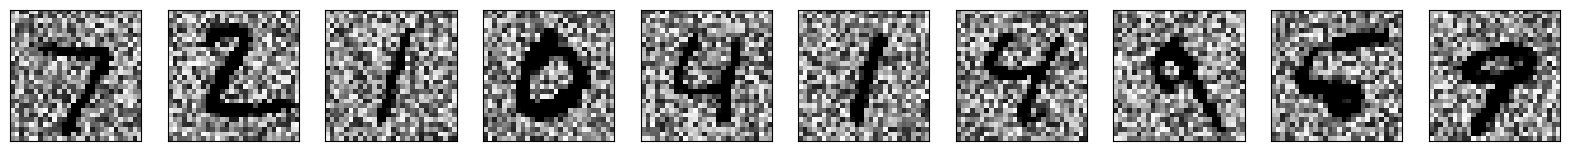

In [13]:
plot(x_test_noisy, None)

### Plot some denoised images

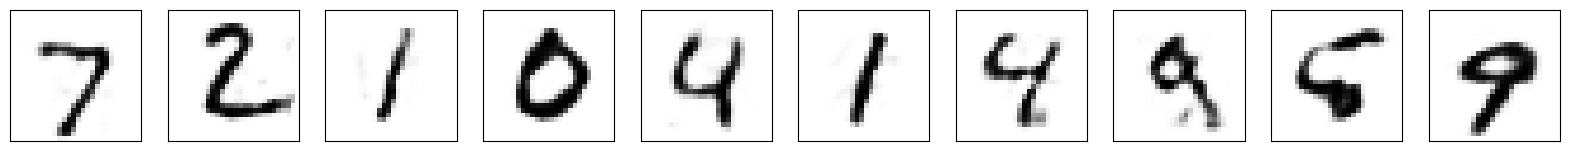

In [14]:
plot(predictions, None)

In [15]:
# evaluate the model on the denoised images
loss, accuracy = classifier.evaluate(predictions, y_test)
print('Accuracy on denoised images:', accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9584 - loss: 0.1350
Accuracy on denoised images: 0.9584000110626221


## Composite Model


In [16]:
# define the input image
input_image = Input(shape=(28 * 28,))

# encode the input image
x = autoencoder(input_image)

# decode the encoded image
y = classifier(x)

# define the denoise and classify model
denoise_and_classify = Model(input_image, y)

In [17]:
# predict the denoised and classified images
predictions = denoise_and_classify.predict(x_test_noisy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


### Noisy Image Classification

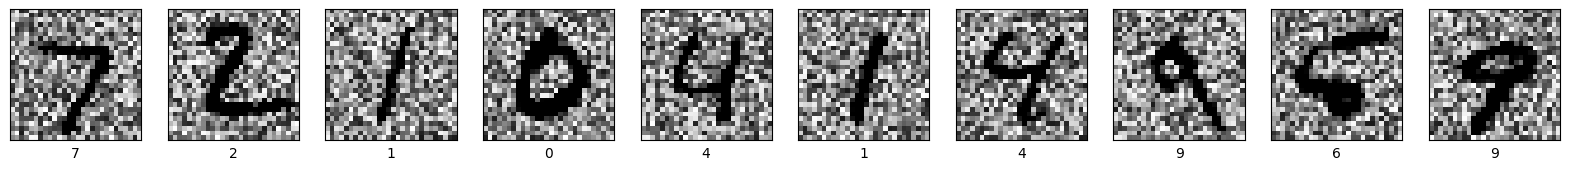

In [18]:
plot(x_test_noisy, predictions, True)

### Denoised Image Classification

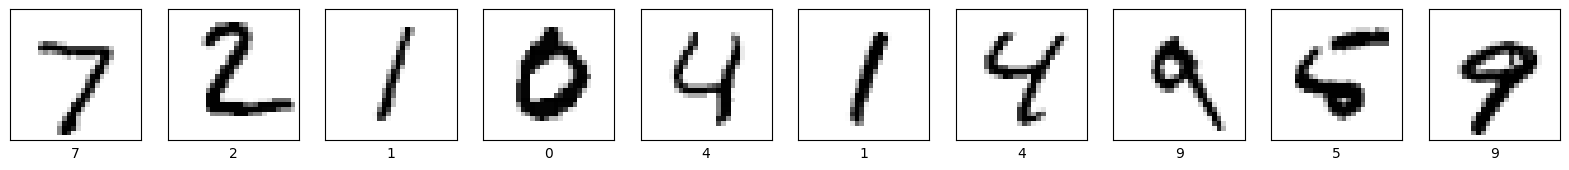

In [19]:
plot(x_test, to_categorical(y_test), True)

In [20]:
# Save both trained models

classifier.save('/content/autodigit_classifier.keras')

autoencoder.save('/content/autodigit_autoencoder.keras')

print("Models saved successfully!")

Models saved successfully!


In [21]:
from google.colab import files

files.download('/content/autodigit_classifier.keras')
files.download('/content/autodigit_autoencoder.keras')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
!pip -q install opencv-python-headless scipy

import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from scipy.ndimage import gaussian_filter
from google.colab import drive

drive.mount('/content/drive')

BASE_DIR = '/content/drive/MyDrive/DigitRescue'

os.makedirs(BASE_DIR, exist_ok=True)

print("DigitRescue environment ready!")

Mounted at /content/drive
DigitRescue environment ready!


In [23]:
from tensorflow.keras.datasets import mnist

(dr_x_train, dr_y_train), (dr_x_test, dr_y_test) = mnist.load_data()

print("Training images:", dr_x_train.shape)
print("Testing images:", dr_x_test.shape)
print("Image size:", dr_x_train.shape[1:])

Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)
Image size: (28, 28)


In [24]:
def create_corrupted(images, noise_type, seed=42):

    rng = np.random.default_rng(seed)

    x = images.astype(np.float32) / 255.0

    if noise_type == "gaussian":
        noise = rng.normal(0, 0.4, x.shape)
        x = np.clip(x + noise, 0, 1)

    elif noise_type == "salt_pepper":
        r = rng.random(x.shape)
        x[r < 0.075] = 0
        x[(r >= 0.075) & (r < 0.15)] = 1

    elif noise_type == "blur":
        x = gaussian_filter(x, sigma=(0, 1.3, 1.3))

    elif noise_type == "fading":
        factors = rng.uniform(0.32, 0.48, (len(x), 1, 1))

        smooth = gaussian_filter(
            rng.random(x.shape),
            sigma=(0, 4, 4)
        )

        low = smooth.min(axis=(1, 2), keepdims=True)
        high = smooth.max(axis=(1, 2), keepdims=True)

        smooth = (smooth - low) / (high - low + 1e-8)

        x = x * factors * (0.5 + 0.5 * smooth)

    elif noise_type == "erasure":

        x = images.copy()

        for i in range(len(x)):
            ys, xs = np.nonzero(images[i] > 80)

            if len(ys) == 0:
                continue

            for _ in range(2):
                k = rng.integers(len(ys))

                h = rng.integers(4, 7)
                w = rng.integers(4, 7)

                top = max(0, ys[k] - h // 2)
                left = max(0, xs[k] - w // 2)

                x[i, top:top+h, left:left+w] = 0

    return np.clip(x * 255, 0, 255).astype(np.uint8)


noise_types = [
    "gaussian",
    "salt_pepper",
    "blur",
    "fading",
    "erasure"
]

dr_corrupted = {}

for i, noise in enumerate(noise_types):

    print("Generating:", noise)

    dr_corrupted[noise] = {
        "train": create_corrupted(
            dr_x_train, noise, 42 + i
        ),
        "test": create_corrupted(
            dr_x_test, noise, 142 + i
        )
    }

print("\nAll five corrupted datasets generated!")

Generating: gaussian
Generating: salt_pepper
Generating: blur
Generating: fading
Generating: erasure

All five corrupted datasets generated!


In [25]:
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(4, 4)
)

def preprocess_image(image, noise_type):

    # Resize image
    image = cv2.resize(image, (28, 28))

    # Median filtering
    if noise_type == "salt_pepper":
        image = cv2.medianBlur(image, 3)

    # Gaussian filtering
    elif noise_type == "gaussian":
        image = cv2.GaussianBlur(image, (3, 3), 0)

    # Unsharp masking for blurred images
    elif noise_type == "blur":
        blurred = cv2.GaussianBlur(image, (0, 0), 1.0)
        image = cv2.addWeighted(image, 1.5, blurred, -0.5, 0)

    # Contrast enhancement
    elif noise_type in ["fading", "erasure"]:
        image = clahe.apply(image)

    return image


# Normalization function: 0 to 255 becomes 0 to 1
def normalize_images(images):
    return images.astype(np.float32) / 255.0

print("Preprocessing functions implemented!")

Preprocessing functions implemented!


In [26]:
dr_processed = {}

for noise in noise_types:

    print("Processing:", noise)

    dr_processed[noise] = {}

    for split in ["train", "test"]:

        original = dr_corrupted[noise][split]

        processed = np.empty_like(original)

        for i in range(len(original)):

            processed[i] = preprocess_image(
                original[i], noise
            )

        dr_processed[noise][split] = processed

print("\nAll five datasets preprocessed successfully!")

Processing: gaussian
Processing: salt_pepper
Processing: blur
Processing: fading
Processing: erasure

All five datasets preprocessed successfully!


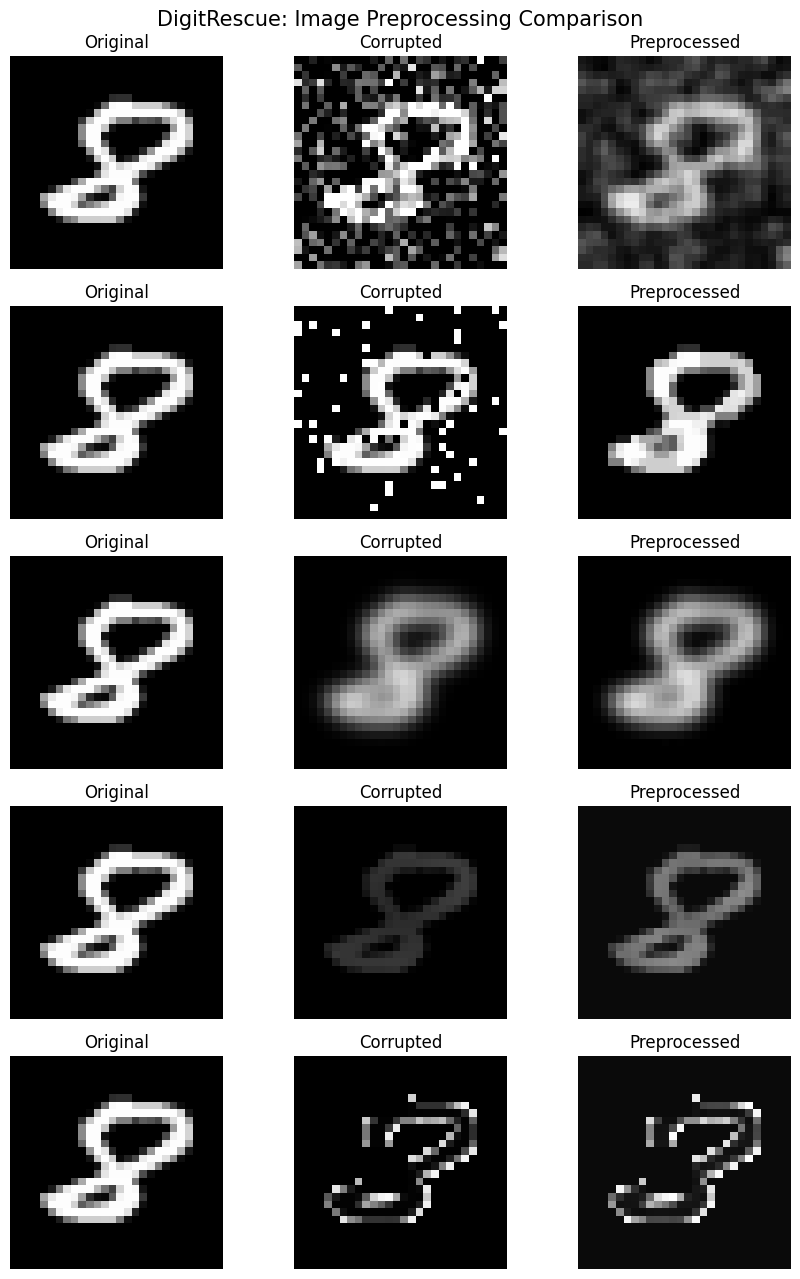

In [27]:
fig, axes = plt.subplots(5, 3, figsize=(9, 13))

for row, noise in enumerate(noise_types):

    index = np.where(dr_y_test == 8)[0][0]

    clean = dr_x_test[index]
    noisy = dr_corrupted[noise]["test"][index]
    processed = dr_processed[noise]["test"][index]

    images = [clean, noisy, processed]

    titles = ["Original", "Corrupted", "Preprocessed"]

    for col in range(3):

        axes[row, col].imshow(
            images[col], cmap="gray", vmin=0, vmax=255
        )

        axes[row, col].set_title(titles[col])
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(noise)

plt.suptitle(
    "DigitRescue: Image Preprocessing Comparison",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [28]:
output_dir = BASE_DIR + "/phase2_processed"

for noise in noise_types:

    folder = output_dir + "/" + noise

    os.makedirs(folder, exist_ok=True)

    np.save(
        folder + "/train_images.npy",
        dr_processed[noise]["train"]
    )

    np.save(
        folder + "/test_images.npy",
        dr_processed[noise]["test"]
    )

print("All processed datasets saved successfully!")

All processed datasets saved successfully!


In [29]:
for noise in noise_types:

    train = dr_processed[noise]["train"]

    normalized = normalize_images(train[:100])

    print("\n", noise)

    print("Shape:", train.shape)

    print("Original range:",
          train.min(), "-", train.max())

    print("Normalized range:",
          normalized.min(), "-", normalized.max())


 gaussian
Shape: (60000, 28, 28)
Original range: 0 - 255
Normalized range: 0.0 - 1.0

 salt_pepper
Shape: (60000, 28, 28)
Original range: 0 - 255
Normalized range: 0.0 - 1.0

 blur
Shape: (60000, 28, 28)
Original range: 0 - 255
Normalized range: 0.0 - 0.9882353

 fading
Shape: (60000, 28, 28)
Original range: 8 - 218
Normalized range: 0.039215688 - 0.7411765

 erasure
Shape: (60000, 28, 28)
Original range: 8 - 255
Normalized range: 0.039215688 - 1.0


In [30]:
def create_erasure_fixed(images, seed=42):

    rng = np.random.default_rng(seed)
    out = images.copy()

    for i in range(len(out)):

        ys, xs = np.nonzero(images[i] > 80)

        if len(ys) == 0:
            continue

        for _ in range(2):

            k = rng.integers(len(ys))

            h = rng.integers(4, 7)
            w = rng.integers(4, 7)

            top = max(0, ys[k] - h // 2)
            left = max(0, xs[k] - w // 2)

            out[i, top:top+h, left:left+w] = 0

    return out


dr_corrupted["erasure"]["train"] = create_erasure_fixed(
    dr_x_train, 46
)

dr_corrupted["erasure"]["test"] = create_erasure_fixed(
    dr_x_test, 146
)

for split in ["train", "test"]:

    processed = np.empty_like(
        dr_corrupted["erasure"][split]
    )

    for i, img in enumerate(dr_corrupted["erasure"][split]):
        processed[i] = preprocess_image(img, "erasure")

    dr_processed["erasure"][split] = processed

print("Erasure dataset corrected!")

print("Unique grayscale values:",
      len(np.unique(dr_corrupted["erasure"]["train"])))

Erasure dataset corrected!
Unique grayscale values: 256


In [31]:
def cnn_ready(images):

    images = images.astype("float32") / 255.0

    return images.reshape(-1, 28, 28, 1)


X_train = cnn_ready(dr_x_train)
X_test = cnn_ready(dr_x_test)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

Training shape: (60000, 28, 28, 1)
Testing shape: (10000, 28, 28, 1)


In [32]:
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D,
    Flatten, Dense, Dropout
)

digitrescue_cnn = Sequential([

    Conv2D(32, (3,3), activation="relu",
           input_shape=(28,28,1)),

    MaxPooling2D((2,2)),

    Conv2D(64, (3,3), activation="relu"),

    MaxPooling2D((2,2)),

    Flatten(),

    Dense(128, activation="relu"),

    Dropout(0.3),

    Dense(10, activation="softmax")

])

digitrescue_cnn.compile(

    optimizer="adam",

    loss="sparse_categorical_crossentropy",

    metrics=["accuracy"]

)

digitrescue_cnn.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [33]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = digitrescue_cnn.fit(

    X_train,
    dr_y_train,

    epochs=10,
    batch_size=128,

    validation_split=0.1,

    callbacks=[early_stop]

)

Epoch 1/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 20s 25ms/step - accuracy: 0.9163 - loss: 0.2745 - val_accuracy: 0.9823 - val_loss: 0.0605
Epoch 2/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9764 - loss: 0.0767 - val_accuracy: 0.9887 - val_loss: 0.0437
Epoch 3/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9834 - loss: 0.0558 - val_accuracy: 0.9893 - val_loss: 0.0400
Epoch 4/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9864 - loss: 0.0438 - val_accuracy: 0.9913 - val_loss: 0.0359
Epoch 5/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9887 - loss: 0.0361 - val_accuracy: 0.9915 - val_loss: 0.0315
Epoch 6/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.9899 - loss: 0.0321 - val_accuracy: 0.9905 - val_loss: 0.0312
Epoch 7/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.9914 - loss: 0.0272 - val_accuracy: 0.9907 - val_loss: 0.0329
Epoch 8/10
422/422 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.9930 - loss: 0.0221 - val_accuracy: 

In [34]:
loss, accuracy = digitrescue_cnn.evaluate(
    X_test,
    dr_y_test,
    verbose=0
)

print("Clean Image Test Accuracy:",
      round(accuracy * 100, 2), "%")

Clean Image Test Accuracy: 99.19 %


In [35]:
results = {}

results["Clean"] = accuracy * 100

for noise in noise_types:

    print("Testing:", noise)

    noisy = cnn_ready(
        dr_corrupted[noise]["test"]
    )

    processed = cnn_ready(
        dr_processed[noise]["test"]
    )

    noisy_acc = digitrescue_cnn.evaluate(
        noisy, dr_y_test, verbose=0
    )[1]

    processed_acc = digitrescue_cnn.evaluate(
        processed, dr_y_test, verbose=0
    )[1]

    results[noise + "_Noisy"] = noisy_acc * 100

    results[noise + "_Preprocessed"] = (
        processed_acc * 100
    )

print("\nCNN ACCURACY COMPARISON")

for name, score in results.items():

    print(name, ":", round(score, 2), "%")

Testing: gaussian
Testing: salt_pepper
Testing: blur
Testing: fading
Testing: erasure

CNN ACCURACY COMPARISON
Clean : 99.19 %
gaussian_Noisy : 85.1 %
gaussian_Preprocessed : 96.65 %
salt_pepper_Noisy : 88.95 %
salt_pepper_Preprocessed : 98.11 %
blur_Noisy : 97.78 %
blur_Preprocessed : 98.32 %
fading_Noisy : 98.36 %
fading_Preprocessed : 99.06 %
erasure_Noisy : 84.96 %
erasure_Preprocessed : 84.97 %


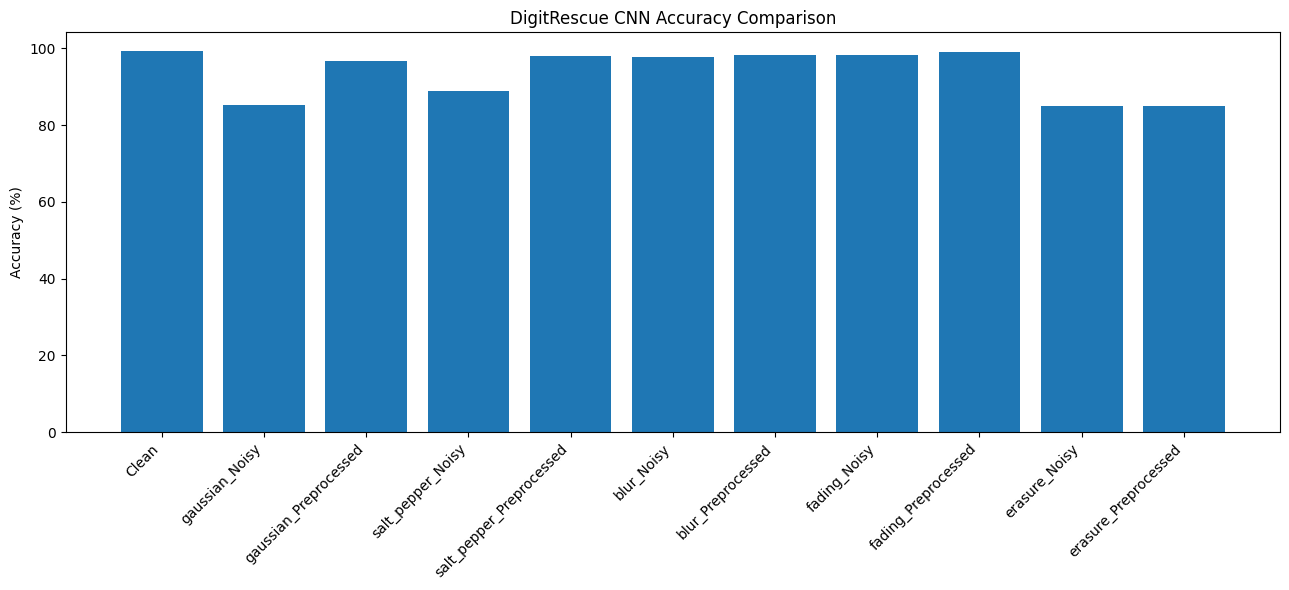

In [36]:
plt.figure(figsize=(13,6))

plt.bar(
    results.keys(),
    results.values()
)

plt.title("DigitRescue CNN Accuracy Comparison")

plt.ylabel("Accuracy (%)")

plt.xticks(rotation=45, ha="right")

plt.tight_layout()

plt.show()

In [37]:
digitrescue_cnn.save(
    BASE_DIR + "/digitrescue_cnn.keras"
)

print("CNN model saved successfully!")

CNN model saved successfully!


In [38]:
import tensorflow as tf
import numpy as np

AUTOTUNE = tf.data.AUTOTUNE

def make_pair_dataset(noisy, clean):

    dataset = tf.data.Dataset.from_tensor_slices(
        (noisy, clean)
    )

    def normalize(noisy_img, clean_img):

        noisy_img = tf.cast(noisy_img, tf.float32) / 255.0
        clean_img = tf.cast(clean_img, tf.float32) / 255.0

        noisy_img = tf.expand_dims(noisy_img, -1)
        clean_img = tf.expand_dims(clean_img, -1)

        return noisy_img, clean_img

    return dataset.map(
        normalize,
        num_parallel_calls=AUTOTUNE
    )


# Prepare training data from all five corruption types

train_parts = []

for noise in noise_types:

    ds = make_pair_dataset(
        dr_corrupted[noise]["train"],
        dr_x_train
    )

    train_parts.append(ds)


train_ds = train_parts[0]

for ds in train_parts[1:]:
    train_ds = train_ds.concatenate(ds)


train_ds = train_ds.shuffle(20000)
train_ds = train_ds.batch(128).prefetch(AUTOTUNE)


# Prepare validation data: 2,000 examples per corruption type

val_parts = []

for noise in noise_types:

    ds = make_pair_dataset(
        dr_corrupted[noise]["test"][:2000],
        dr_x_test[:2000]
    )

    val_parts.append(ds)


val_ds = val_parts[0]

for ds in val_parts[1:]:
    val_ds = val_ds.concatenate(ds)


val_ds = val_ds.batch(128).prefetch(AUTOTUNE)


print("Training samples:", 300000)
print("Validation samples:", 10000)

Training samples: 300000
Validation samples: 10000


In [39]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D, UpSampling2D
)

inputs = Input(shape=(28, 28, 1))

# Encoder

x = Conv2D(32, (3,3), activation="relu",
           padding="same")(inputs)

x = MaxPooling2D((2,2), padding="same")(x)

x = Conv2D(64, (3,3), activation="relu",
           padding="same")(x)

x = MaxPooling2D((2,2), padding="same")(x)


# Decoder

x = Conv2D(64, (3,3), activation="relu",
           padding="same")(x)

x = UpSampling2D((2,2))(x)

x = Conv2D(32, (3,3), activation="relu",
           padding="same")(x)

x = UpSampling2D((2,2))(x)

outputs = Conv2D(
    1, (3,3),
    activation="sigmoid",
    padding="same"
)(x)


digitrescue_autoencoder = Model(
    inputs,
    outputs,
    name="DigitRescue_Denoising_Autoencoder"
)


digitrescue_autoencoder.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)


digitrescue_autoencoder.summary()

Model: "DigitRescue_Denoising_Autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 14, 14, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,497 (291.00 KB)

 Trainable params: 74,497 (291.00 KB)

 Non-trainable params: 0 (0.00 B)

In [40]:
from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

callbacks = [

    EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2
    )
]


dae_history = digitrescue_autoencoder.fit(

    train_ds,

    validation_data=val_ds,

    epochs=15,

    callbacks=callbacks
)

Epoch 1/15
2344/2344 ━━━━━━━━━━━━━━━━━━━━ 47s 15ms/step - loss: 0.1122 - mae: 0.1313 - val_loss: 0.1025 - val_mae: 0.1209 - learning_rate: 0.0010
Epoch 2/15
2344/2344 ━━━━━━━━━━━━━━━━━━━━ 23s 9ms/step - loss: 0.1120 - mae: 0.1307 - val_loss: 0.1025 - val_mae: 0.1209 - learning_rate: 0.0010
Epoch 3/15
2344/2344 ━━━━━━━━━━━━━━━━━━━━ 23s 10ms/step - loss: 0.1120 - mae: 0.1307 - val_loss: 0.1025 - val_mae: 0.1209 - learning_rate: 0.0010
Epoch 4/15
2344/2344 ━━━━━━━━━━━━━━━━━━━━ 22s 9ms/step - loss: 0.1120 - mae: 0.1307 - val_loss: 0.1025 - val_mae: 0.1209 - learning_rate: 5.0000e-04
Epoch 5/15
2344/2344 ━━━━━━━━━━━━━━━━━━━━ 24s 10ms/step - loss: 0.1120 - mae: 0.1307 - val_loss: 0.1025 - val_mae: 0.1209 - learning_rate: 5.0000e-04


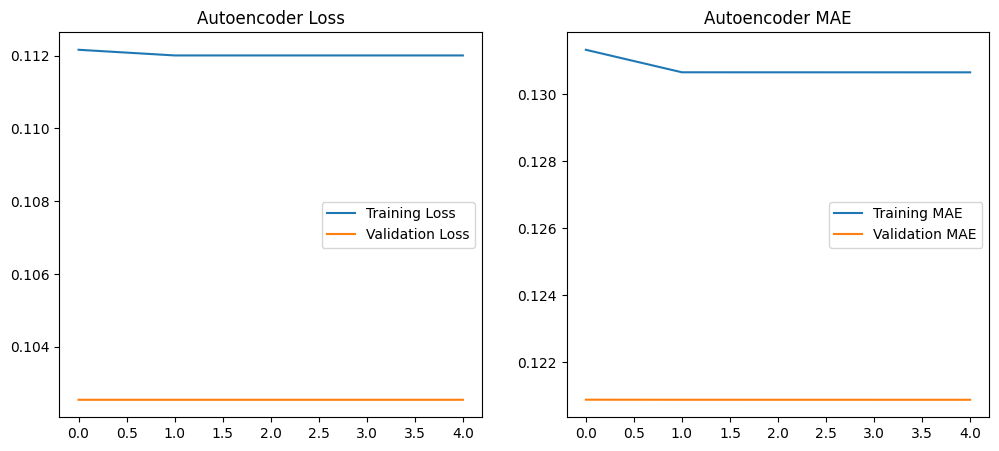

In [41]:
plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.plot(dae_history.history["loss"],
         label="Training Loss")

plt.plot(dae_history.history["val_loss"],
         label="Validation Loss")

plt.title("Autoencoder Loss")
plt.legend()


plt.subplot(1,2,2)

plt.plot(dae_history.history["mae"],
         label="Training MAE")

plt.plot(dae_history.history["val_mae"],
         label="Validation MAE")

plt.title("Autoencoder MAE")
plt.legend()

plt.show()

In [42]:
digitrescue_autoencoder.save(
    BASE_DIR + "/digitrescue_autoencoder.keras"
)

print("Denoising Autoencoder saved successfully!")

Denoising Autoencoder saved successfully!


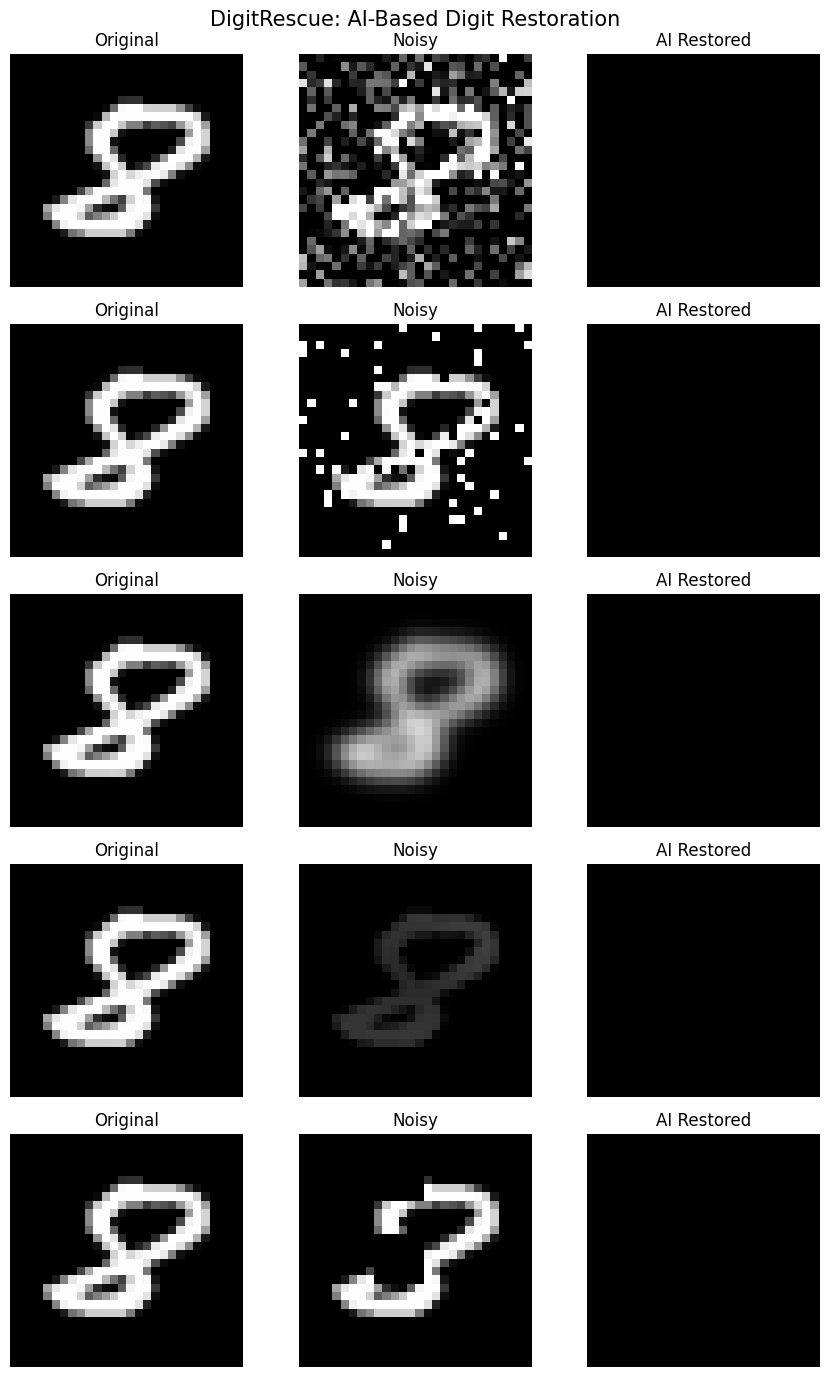

In [43]:
fig, axes = plt.subplots(5, 3, figsize=(9, 14))

index = np.where(dr_y_test == 8)[0][0]

for row, noise in enumerate(noise_types):

    clean = dr_x_test[index]

    noisy = dr_corrupted[noise]["test"][index]

    model_input = (
        noisy.astype("float32")[None, ..., None] / 255.0
    )

    restored = digitrescue_autoencoder.predict(
        model_input,
        verbose=0
    )[0, :, :, 0]


    images = [
        clean / 255.0,
        noisy / 255.0,
        restored
    ]

    titles = ["Original", "Noisy", "AI Restored"]

    for col in range(3):

        axes[row, col].imshow(
            images[col],
            cmap="gray",
            vmin=0,
            vmax=1
        )

        axes[row, col].set_title(titles[col])
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(noise)


plt.suptitle(
    "DigitRescue: AI-Based Digit Restoration",
    fontsize=15
)

plt.tight_layout()
plt.show()

In [44]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt

RESULT_DIR = BASE_DIR + "/phase5_results"

os.makedirs(RESULT_DIR, exist_ok=True)

print("Phase 5 evaluation environment ready!")

Phase 5 evaluation environment ready!


In [45]:
def calculate_accuracy(images, labels):

    X = images.astype("float32") / 255.0
    X = X.reshape(-1, 28, 28, 1)

    predictions = digitrescue_cnn.predict(
        X, batch_size=256, verbose=0
    )

    predicted_labels = np.argmax(predictions, axis=1)

    accuracy = np.mean(predicted_labels == labels)

    return accuracy * 100


clean_accuracy = calculate_accuracy(
    dr_x_test, dr_y_test
)

print("Clean Image Accuracy:",
      round(clean_accuracy, 2), "%")

Clean Image Accuracy: 99.19 %


In [46]:
results_phase5 = {}

restored_images = {}

for noise in noise_types:

    print("\nEvaluating:", noise)

    # Original noisy images
    noisy = dr_corrupted[noise]["test"]

    # Preprocessed images
    processed = dr_processed[noise]["test"]

    # AI restoration
    noisy_input = noisy.astype("float32") / 255.0

    noisy_input = noisy_input.reshape(-1, 28, 28, 1)

    restored = digitrescue_autoencoder.predict(
        noisy_input,
        batch_size=256,
        verbose=0
    )

    restored = np.clip(restored[:, :, :, 0] * 255, 0, 255)
    restored = restored.astype("uint8")

    # Save restored images for future use
    restored_images[noise] = restored

    np.save(
        RESULT_DIR + f"/{noise}_restored.npy",
        restored
    )

    # Calculate recognition accuracy
    noisy_acc = calculate_accuracy(
        noisy, dr_y_test
    )

    processed_acc = calculate_accuracy(
        processed, dr_y_test
    )

    restored_acc = calculate_accuracy(
        restored, dr_y_test
    )

    results_phase5[noise] = {
        "Noisy": noisy_acc,
        "Preprocessed": processed_acc,
        "AI Restored": restored_acc
    }

    print("Noisy Accuracy:", round(noisy_acc, 2), "%")
    print("Preprocessed Accuracy:", round(processed_acc, 2), "%")
    print("AI Restored Accuracy:", round(restored_acc, 2), "%")

print("\nAll experiments completed!")


Evaluating: gaussian
Noisy Accuracy: 85.1 %
Preprocessed Accuracy: 96.65 %
AI Restored Accuracy: 11.35 %

Evaluating: salt_pepper
Noisy Accuracy: 88.95 %
Preprocessed Accuracy: 98.11 %
AI Restored Accuracy: 11.35 %

Evaluating: blur
Noisy Accuracy: 97.78 %
Preprocessed Accuracy: 98.32 %
AI Restored Accuracy: 11.35 %

Evaluating: fading
Noisy Accuracy: 98.36 %
Preprocessed Accuracy: 99.06 %
AI Restored Accuracy: 11.35 %

Evaluating: erasure
Noisy Accuracy: 84.96 %
Preprocessed Accuracy: 84.97 %
AI Restored Accuracy: 11.35 %

All experiments completed!


In [47]:
def calculate_psnr(clean, restored):

    clean = clean.astype("float32") / 255.0
    restored = restored.astype("float32") / 255.0

    mse = np.mean((clean - restored) ** 2)

    if mse == 0:
        return float("inf")

    return 10 * np.log10(1.0 / mse)


psnr_results = {}

for noise in noise_types:

    noisy_psnr = calculate_psnr(
        dr_x_test,
        dr_corrupted[noise]["test"]
    )

    restored_psnr = calculate_psnr(
        dr_x_test,
        restored_images[noise]
    )

    psnr_results[noise] = {
        "Noisy PSNR": noisy_psnr,
        "Restored PSNR": restored_psnr
    }

    print("\n", noise)

    print("Noisy PSNR:",
          round(noisy_psnr, 2), "dB")

    print("Restored PSNR:",
          round(restored_psnr, 2), "dB")


 gaussian
Noisy PSNR: 11.01 dB
Restored PSNR: 9.43 dB

 salt_pepper
Noisy PSNR: 11.42 dB
Restored PSNR: 9.43 dB

 blur
Noisy PSNR: 16.81 dB
Restored PSNR: 9.43 dB

 fading
Noisy PSNR: 12.48 dB
Restored PSNR: 9.43 dB

 erasure
Noisy PSNR: 15.78 dB
Restored PSNR: 9.43 dB


In [48]:
comparison = []

for noise in noise_types:

    comparison.append({

        "Corruption": noise,

        "Noisy Accuracy (%)":
        results_phase5[noise]["Noisy"],

        "Preprocessed Accuracy (%)":
        results_phase5[noise]["Preprocessed"],

        "AI Restored Accuracy (%)":
        results_phase5[noise]["AI Restored"]

    })


df_results = pd.DataFrame(comparison)

print("CLEAN IMAGE ACCURACY:", round(clean_accuracy, 2), "%")

display(df_results.round(2))

CLEAN IMAGE ACCURACY: 99.19 %


,Corruption,Noisy Accuracy (%),Preprocessed Accuracy (%),AI Restored Accuracy (%)
0,gaussian,85.10,96.65,11.35
1,salt_pepper,88.95,98.11,11.35
2,blur,97.78,98.32,11.35
3,fading,98.36,99.06,11.35
4,erasure,84.96,84.97,11.35


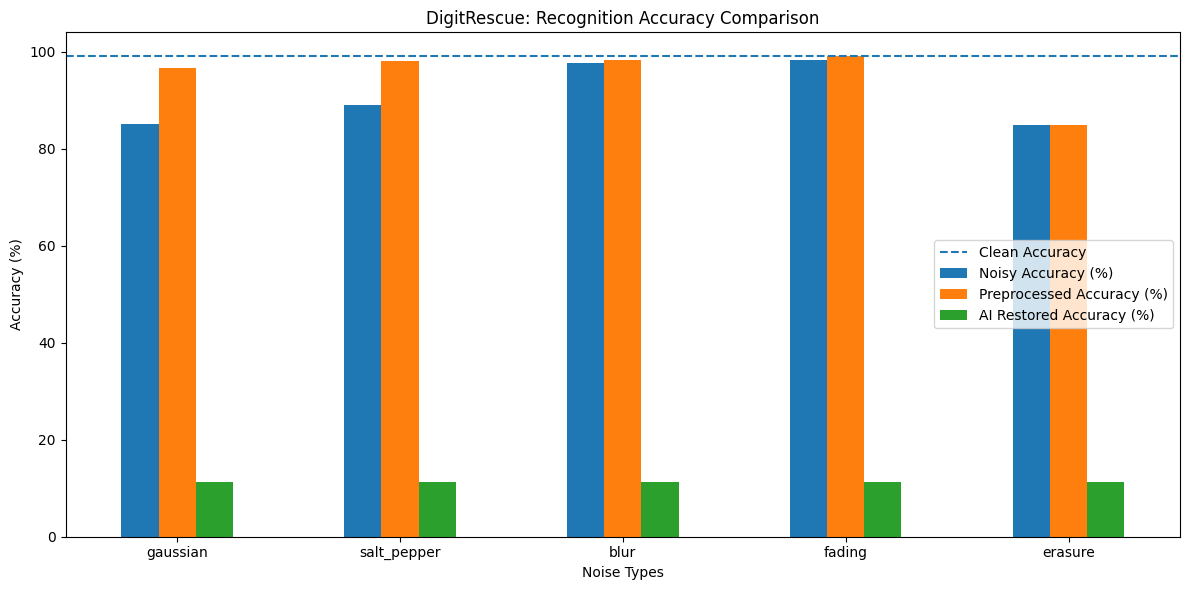

In [49]:
df_results.set_index("Corruption")[
    [
        "Noisy Accuracy (%)",
        "Preprocessed Accuracy (%)",
        "AI Restored Accuracy (%)"
    ]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.axhline(
    clean_accuracy,
    linestyle="--",
    label="Clean Accuracy"
)

plt.title("DigitRescue: Recognition Accuracy Comparison")

plt.ylabel("Accuracy (%)")

plt.xlabel("Noise Types")

plt.xticks(rotation=0)

plt.legend()

plt.tight_layout()

plt.show()

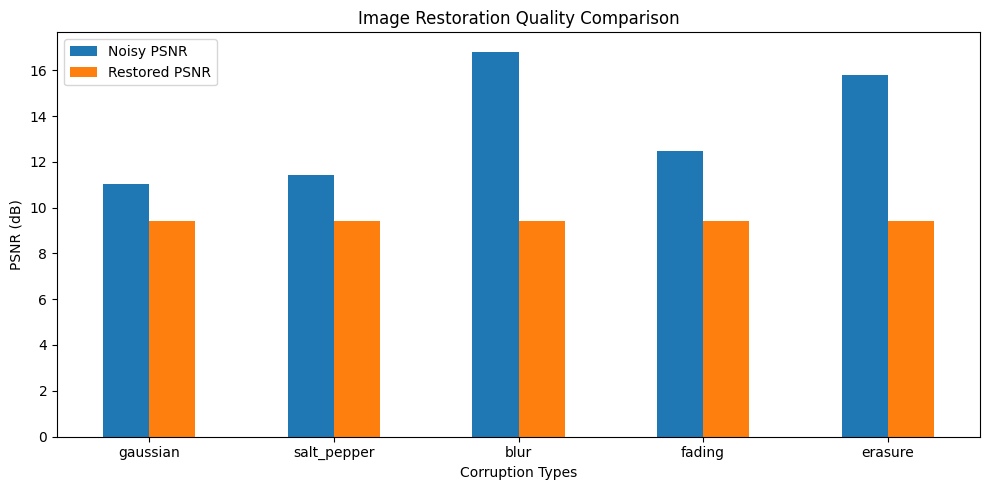

In [50]:
psnr_df = pd.DataFrame(psnr_results).T

psnr_df.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Image Restoration Quality Comparison")

plt.ylabel("PSNR (dB)")

plt.xlabel("Corruption Types")

plt.xticks(rotation=0)

plt.legend()

plt.tight_layout()

plt.show()

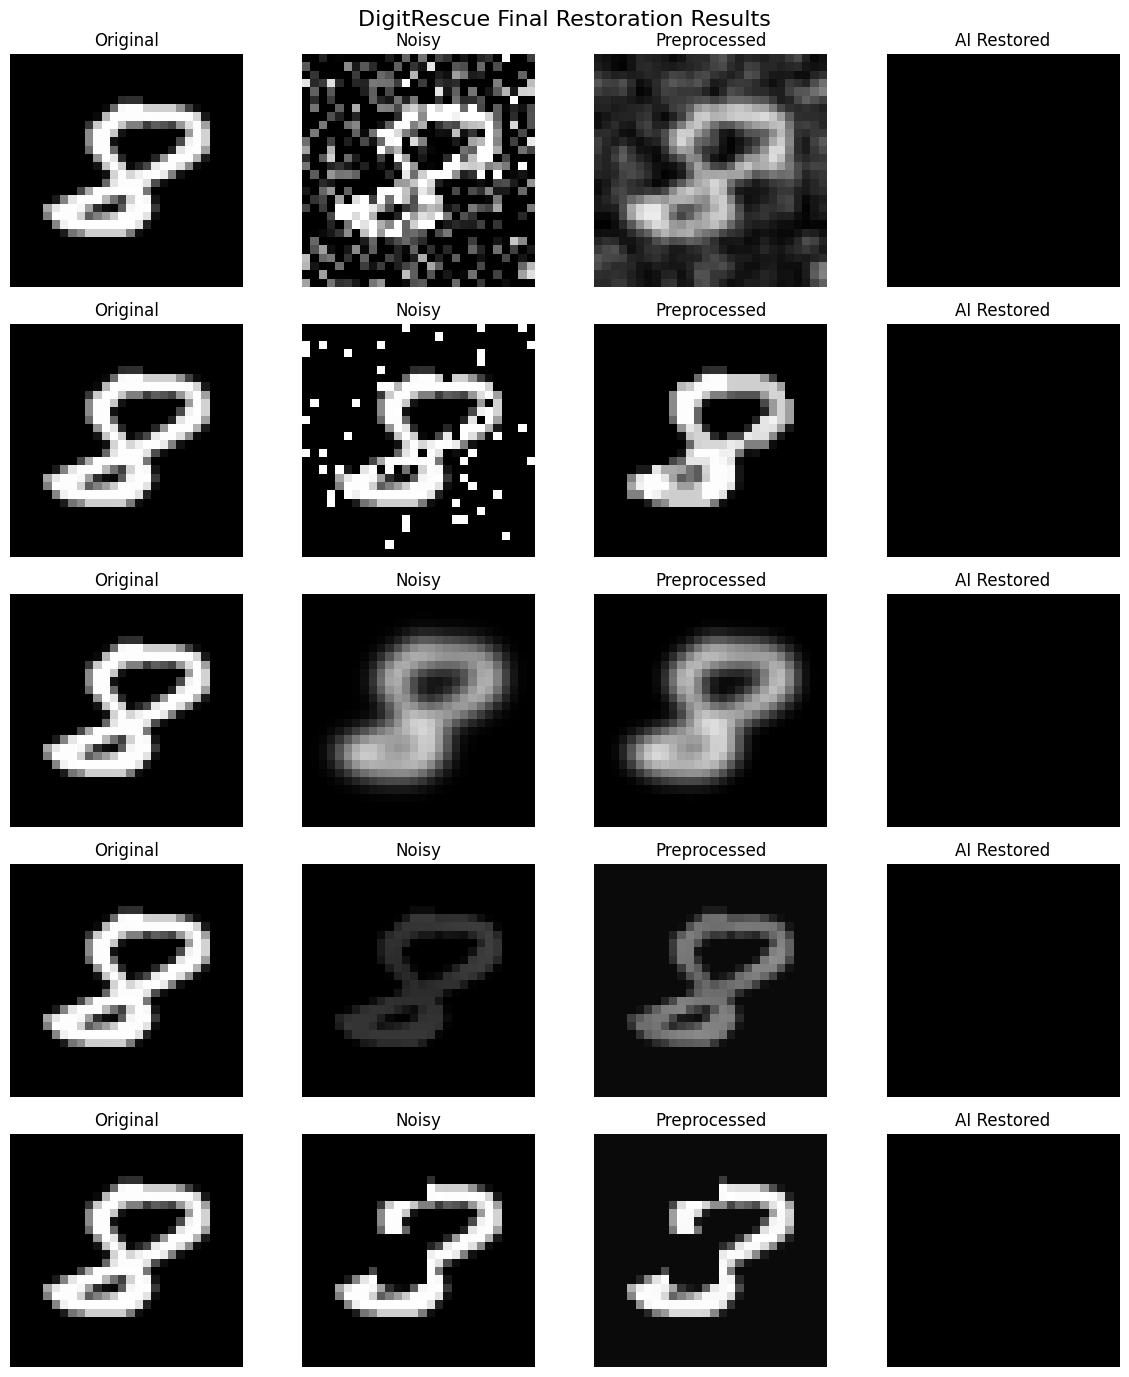

In [51]:
index = np.where(dr_y_test == 8)[0][0]

fig, axes = plt.subplots(5, 4, figsize=(12, 14))

for row, noise in enumerate(noise_types):

    images = [
        dr_x_test[index],
        dr_corrupted[noise]["test"][index],
        dr_processed[noise]["test"][index],
        restored_images[noise][index]
    ]

    titles = [
        "Original",
        "Noisy",
        "Preprocessed",
        "AI Restored"
    ]

    for col in range(4):

        axes[row, col].imshow(
            images[col],
            cmap="gray",
            vmin=0,
            vmax=255
        )

        axes[row, col].set_title(titles[col])
        axes[row, col].axis("off")

    axes[row, 0].set_ylabel(noise)

plt.suptitle(
    "DigitRescue Final Restoration Results",
    fontsize=16
)

plt.tight_layout()

plt.show()

In [52]:
df_results.to_csv(
    RESULT_DIR + "/accuracy_comparison.csv",
    index=False
)

psnr_df.to_csv(
    RESULT_DIR + "/psnr_comparison.csv"
)

print("Experimental results saved!")

print("Location:", RESULT_DIR)

Experimental results saved!
Location: /content/drive/MyDrive/DigitRescue/phase5_results


In [53]:
import os

cnn_path = BASE_DIR + "/digitrescue_cnn.keras"

autoencoder_path = BASE_DIR + "/digitrescue_autoencoder.keras"

print("CNN Model:", os.path.exists(cnn_path))
print("Autoencoder Model:", os.path.exists(autoencoder_path))

print("\nModel sizes:")

print("CNN:", round(os.path.getsize(cnn_path)/1024, 2), "KB")

print("Autoencoder:",
      round(os.path.getsize(autoencoder_path)/1024, 2), "KB")

CNN Model: True
Autoencoder Model: True

Model sizes:
CNN: 2675.82 KB
Autoencoder: 921.23 KB


In [54]:
%%writefile /content/drive/MyDrive/DigitRescue/app.py

import streamlit as st
import tensorflow as tf
import numpy as np
import cv2

from PIL import Image
from pathlib import Path
from io import BytesIO

BASE_DIR = Path(__file__).resolve().parent

CNN_PATH = BASE_DIR / "digitrescue_cnn.keras"
AUTOENCODER_PATH = BASE_DIR / "digitrescue_autoencoder.keras"


st.set_page_config(
    page_title="DigitRescue AI",
    page_icon="🔢",
    layout="wide"
)


@st.cache_resource
def load_models():

    cnn = tf.keras.models.load_model(CNN_PATH)

    autoencoder = tf.keras.models.load_model(
        AUTOENCODER_PATH
    )

    return cnn, autoencoder


def prepare_digit(image):

    image = image.convert("RGB")

    image = np.array(image)

    gray = cv2.cvtColor(
        image,
        cv2.COLOR_RGB2GRAY
    )

    # Convert dark handwriting on white paper
    # into MNIST-style white digits on black background.

    border = np.concatenate([
        gray[0, :],
        gray[-1, :],
        gray[:, 0],
        gray[:, -1]
    ])

    if np.mean(border) > 127:

        gray = 255 - gray

    # Find digit boundaries

    _, mask = cv2.threshold(
        gray,
        0,
        255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    points = cv2.findNonZero(mask)

    if points is None:

        return cv2.resize(gray, (28, 28))

    x, y, w, h = cv2.boundingRect(points)

    digit = gray[y:y+h, x:x+w]

    # Resize while maintaining aspect ratio

    scale = 20 / max(w, h)

    new_w = max(1, int(w * scale))

    new_h = max(1, int(h * scale))

    digit = cv2.resize(
        digit,
        (new_w, new_h)
    )

    # Center digit inside 28x28 image

    canvas = np.zeros((28, 28), dtype=np.uint8)

    x_offset = (28 - new_w) // 2

    y_offset = (28 - new_h) // 2

    canvas[
        y_offset:y_offset+new_h,
        x_offset:x_offset+new_w
    ] = digit

    return canvas


def preprocess_image(image, noise_type):

    if noise_type == "Gaussian Noise":

        return cv2.GaussianBlur(
            image, (3, 3), 0
        )

    elif noise_type == "Salt and Pepper":

        return cv2.medianBlur(image, 3)

    elif noise_type == "Blur":

        blurred = cv2.GaussianBlur(
            image, (0, 0), 1.0
        )

        return cv2.addWeighted(
            image, 1.5, blurred, -0.5, 0
        )

    elif noise_type in ["Fading", "Erasure"]:

        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(4, 4)
        )

        return clahe.apply(image)

    return image


def predict_digit(model, image):

    x = image.astype("float32") / 255.0

    x = x.reshape(1, 28, 28, 1)

    prediction = model.predict(
        x, verbose=0
    )[0]

    digit = int(np.argmax(prediction))

    confidence = float(prediction[digit]) * 100

    return digit, confidence


st.title("🔢 DigitRescue AI")

st.subheader(
    "AI-Based Restoration and Recognition of Noisy Handwritten Digits"
)

st.write(
    "Upload a damaged handwritten digit. "
    "DigitRescue uses image processing, CNN and "
    "a Denoising Autoencoder to restore and recognize it."
)

st.divider()


# Load models

try:

    cnn, autoencoder = load_models()

    st.success("AI models loaded successfully!")

except Exception as error:

    st.error(f"Could not load models: {error}")

    st.stop()


# Sidebar

st.sidebar.header("Settings")

noise_type = st.sidebar.selectbox(

    "Select the image damage type",

    [
        "Gaussian Noise",
        "Salt and Pepper",
        "Blur",
        "Fading",
        "Erasure"
    ]

)


uploaded_file = st.file_uploader(

    "Upload a handwritten digit image",

    type=["png", "jpg", "jpeg"]

)


if uploaded_file is not None:

    original_image = Image.open(uploaded_file)

    digit_image = prepare_digit(original_image)

    processed_image = preprocess_image(
        digit_image.copy(),
        noise_type
    )


    # CNN predictions

    original_digit, original_confidence = predict_digit(
        cnn, digit_image
    )

    processed_digit, processed_confidence = predict_digit(
        cnn, processed_image
    )


    # AI Restoration

    autoencoder_input = (
        digit_image.astype("float32") / 255.0
    )

    autoencoder_input = autoencoder_input.reshape(
        1, 28, 28, 1
    )

    restored = autoencoder.predict(
        autoencoder_input,
        verbose=0
    )[0, :, :, 0]


    restored_image = np.clip(
        restored * 255, 0, 255
    ).astype("uint8")


    restored_digit, restored_confidence = predict_digit(
        cnn, restored_image
    )


    st.divider()

    st.subheader("Image Restoration Results")


    col1, col2, col3, col4 = st.columns(4)


    with col1:

        st.write("Uploaded Image")

        st.image(
            original_image,
            width="stretch"
        )


    with col2:

        st.write("Preprocessed Image")

        st.image(
            processed_image,
            clamp=True,
            width="stretch"
        )


    with col3:

        st.write("AI Restored Image")

        st.image(
            restored_image,
            clamp=True,
            width="stretch"
        )


    with col4:

        st.write("Final Recognition")

        st.metric(
            "Predicted Digit",
            restored_digit
        )

        st.metric(
            "Model Confidence",
            f"{restored_confidence:.2f}%"
        )


    st.divider()

    st.subheader("Recognition Comparison")


    results = {

        "Original / Uploaded": (
            original_digit,
            original_confidence
        ),

        "Preprocessed": (
            processed_digit,
            processed_confidence
        ),

        "AI Restored": (
            restored_digit,
            restored_confidence
        )

    }


    for name, result in results.items():

        st.write(
            f"**{name}:** Digit {result[0]} "
            f"({result[1]:.2f}% confidence)"
        )


    # Download restored image

    buffer = BytesIO()

    Image.fromarray(restored_image).save(
        buffer, format="PNG"
    )

    st.download_button(

        "Download Restored Image",

        data=buffer.getvalue(),

        file_name="digitrescue_restored.png",

        mime="image/png"

    )


else:

    st.info(
        "Upload a handwritten digit image to start restoration."
    )


st.divider()

st.caption(
    "DigitRescue | Machine Learning Project | MNIST + CNN + Denoising Autoencoder"
)

Writing /content/drive/MyDrive/DigitRescue/app.py


In [55]:
requirements = """
tensorflow
streamlit
numpy
opencv-python-headless
pillow
"""

requirements_path = BASE_DIR + "/requirements.txt"

with open(requirements_path, "w") as f:

    f.write(requirements)

print("Requirements file created!")

Requirements file created!


In [56]:
import zipfile
import os

zip_path = "/content/DigitRescue_Final_Project.zip"

files_to_include = [

    "app.py",
    "requirements.txt",
    "digitrescue_cnn.keras",
    "digitrescue_autoencoder.keras"
]

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as zipf:

    for filename in files_to_include:

        path = os.path.join(BASE_DIR, filename)

        if os.path.exists(path):

            zipf.write(
                path,
                arcname=filename
            )

    results_folder = BASE_DIR + "/phase5_results"

    if os.path.exists(results_folder):

        for root, dirs, files in os.walk(results_folder):

            for file in files:

                full_path = os.path.join(root, file)

                arcname = os.path.relpath(
                    full_path, BASE_DIR
                )

                zipf.write(full_path, arcname)


print("Complete DigitRescue project packaged!")
print(zip_path)

Complete DigitRescue project packaged!
/content/DigitRescue_Final_Project.zip


In [57]:
from google.colab import files

files.download(
    "/content/DigitRescue_Final_Project.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [58]:
import pandas as pd
import os

results_dir = BASE_DIR + "/phase5_results"

os.makedirs(results_dir, exist_ok=True)

# Save clean accuracy
pd.DataFrame([{
    "metric": "Clean Accuracy",
    "accuracy_percent": clean_accuracy,
    "test_images": len(dr_y_test)
}]).to_csv(
    results_dir + "/summary_metrics.csv",
    index=False
)

# Save CNN training history
pd.DataFrame(history.history).to_csv(
    results_dir + "/cnn_training_history.csv",
    index_label="epoch"
)

# Save Autoencoder training history
pd.DataFrame(dae_history.history).to_csv(
    results_dir + "/autoencoder_training_history.csv",
    index_label="epoch"
)

print("All experimental records saved!")

All experimental records saved!
